# Sesión 3 · Python para IA: numpy, pandas y scikit-learn
**IA aplicada a la ciberseguridad · Máster en Ciberseguridad**

| Parte | Qué haces |
|---|---|
| A | numpy: forma, ejes, máscaras, broadcasting y distancias |
| B | pandas: limpiar y explorar flujos de red al estilo CICIDS2017 |
| C | scikit-learn: baseline, regresión logística y árbol con la misma API |
| D | k-NN a mano con numpy, comparado con scikit-learn |
| E | Guardar y servir un modelo con joblib |
| F | Ampliación: del log de autenticación a un detector |

> **Dos rutas en este cuaderno.** La **ruta base** ejecuta y observa: cada parte explica qué deberías ver. Los bloques **Reto avanzado** son opcionales y piden método.
>
> Ruta base: partes A a E. Ruta avanzada: retos de cada parte y parte F.
>
> Ejecuta las celdas **en orden** (`Mayús + Intro`). En Colab, si se desconecta el entorno, vuelve a ejecutar la preparación.

## Preparación

In [3]:
# Preparación del entorno: ejecuta esta celda la primera (Colab, VS Code o Codespaces)
import sys, os, subprocess, importlib.util

paquetes = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "joblib": "joblib", "xgboost": "xgboost", "lightgbm": "lightgbm"}
faltan = [pip for mod, pip in paquetes.items() if importlib.util.find_spec(mod) is None]

if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])

# Funciones del curso en ia_utils.py (no modifica tu utils.py)
IA_UTILS = "\"\"\"Funciones del curso IA aplicada a la ciberseguridad (sesiones 3 a 6).\"\"\"\nimport os, re, urllib.request\nimport numpy as np\nimport pandas as pd\n\nNSL_URL = \"https://raw.githubusercontent.com/defcom17/NSL_KDD/master/\"\nNSL_COLS = [\"duration\",\"protocol_type\",\"service\",\"flag\",\"src_bytes\",\"dst_bytes\",\"land\",\n  \"wrong_fragment\",\"urgent\",\"hot\",\"num_failed_logins\",\"logged_in\",\"num_compromised\",\n  \"root_shell\",\"su_attempted\",\"num_root\",\"num_file_creations\",\"num_shells\",\n  \"num_access_files\",\"num_outbound_cmds\",\"is_host_login\",\"is_guest_login\",\"count\",\n  \"srv_count\",\"serror_rate\",\"srv_serror_rate\",\"rerror_rate\",\"srv_rerror_rate\",\n  \"same_srv_rate\",\"diff_srv_rate\",\"srv_diff_host_rate\",\"dst_host_count\",\n  \"dst_host_srv_count\",\"dst_host_same_srv_rate\",\"dst_host_diff_srv_rate\",\n  \"dst_host_same_src_port_rate\",\"dst_host_srv_diff_host_rate\",\"dst_host_serror_rate\",\n  \"dst_host_srv_serror_rate\",\"dst_host_rerror_rate\",\"dst_host_srv_rerror_rate\",\n  \"label\",\"difficulty\"]\n\n\ndef load_nsl_kdd(split=\"train\", base=\"data\"):\n    \"\"\"Carga NSL-KDD y añade la columna is_attack. Descarga los ficheros si faltan.\"\"\"\n    name = \"KDDTrain+.txt\" if split == \"train\" else \"KDDTest+.txt\"\n    path = os.path.join(base, name)\n    if not os.path.exists(path):\n        os.makedirs(base, exist_ok=True)\n        urllib.request.urlretrieve(NSL_URL + name.replace(\"+\", \"%2B\"), path)\n    df = pd.read_csv(path, header=None, names=NSL_COLS)\n    df[\"is_attack\"] = (df[\"label\"] != \"normal\").astype(int)\n    return df\n\n\nATTACK_MAP = {\"normal\": \"normal\",\n  **{a: \"dos\" for a in [\"back\", \"land\", \"neptune\", \"pod\", \"smurf\", \"teardrop\",\n                        \"apache2\", \"udpstorm\", \"processtable\", \"mailbomb\"]},\n  **{a: \"probe\" for a in [\"satan\", \"ipsweep\", \"nmap\", \"portsweep\", \"mscan\", \"saint\"]},\n  **{a: \"r2l\" for a in [\"guess_passwd\", \"ftp_write\", \"imap\", \"phf\", \"multihop\",\n                        \"warezmaster\", \"warezclient\", \"spy\", \"xlock\", \"xsnoop\",\n                        \"snmpguess\", \"snmpgetattack\", \"httptunnel\", \"sendmail\",\n                        \"named\", \"worm\"]},\n  **{a: \"u2r\" for a in [\"buffer_overflow\", \"loadmodule\", \"rootkit\", \"perl\",\n                        \"sqlattack\", \"xterm\", \"ps\"]}}\n\n\ndef add_category(df):\n    \"\"\"Añade la columna category: normal, dos, probe, r2l o u2r.\"\"\"\n    df[\"category\"] = df[\"label\"].map(ATTACK_MAP)\n    return df\n\n\ndef generar_flujos(n=60_000, frac_ataque=0.25, seed=0, cambio_herramienta=False):\n    \"\"\"Flujos de red sintéticos con columnas al estilo CICIDS2017, incluidos sus defectos\n    (espacios en los nombres, infinitos, nulos y duplicados). Etiquetas BENIGN / DDoS.\n    Con cambio_herramienta=True el ataque llega en dos episodios con herramientas distintas.\"\"\"\n    rng = np.random.default_rng(seed)\n    nb, na = int(n * (1 - frac_ataque)), int(n * frac_ataque)\n    t0 = pd.Timestamp(\"2017-07-07 09:00:00\")\n    # --- tráfico benigno\n    port_b = rng.choice([443, 80, 53, 22, 8080, 3389, 0], nb, p=[.40, .20, .20, .05, .05, .02, .08])\n    port_b = np.where(port_b == 0, rng.integers(1024, 65535, nb), port_b)\n    dur_b = np.where(rng.random(nb) < 0.02, 0, rng.lognormal(11, 2, nb)).astype(int)\n    fwd_b = rng.poisson(8, nb) + 1\n    bwd_b = rng.poisson(7, nb)\n    fwl_b = np.where(rng.random(nb) < 0.15, rng.uniform(0, 10, nb), rng.normal(400, 250, nb)).clip(0)\n    bwl_b = rng.normal(700, 400, nb).clip(0)\n    syn_b = (rng.random(nb) < 0.3).astype(int)\n    win_b = rng.choice([29200, 65535, 8192, 14600, 64240, -1], nb, p=[.25, .25, .15, .1, .15, .1])\n    ts_b = rng.uniform(0, 8 * 3600, nb)\n    # --- ataque\n    if cambio_herramienta:\n        epi = rng.random(na) < 0.5\n        ts_a = np.where(epi, rng.uniform(1 * 3600, 2 * 3600, na), rng.uniform(5 * 3600, 6 * 3600, na))\n        port_a = np.where(epi, 80, rng.choice([8080, 443], na))\n        win_a = np.where(epi, 8192, rng.choice([29200, 65535, 64240], na))\n        fwl_a = np.where(epi, rng.normal(8, 6, na), rng.normal(60, 40, na)).clip(0)\n    else:\n        ts_a = rng.uniform(6.9 * 3600, 7.3 * 3600, na)\n        port_a = np.where(rng.random(na) < 0.9, 80, 443)\n        win_a = np.where(rng.random(na) < 0.95, 8192, 29200)\n        fwl_a = rng.normal(8, 6, na).clip(0)\n    dur_a = rng.lognormal(13, 1.5, na).astype(int)\n    fwd_a = rng.poisson(4, na) + 1\n    bwd_a = rng.poisson(3, na)\n    bwl_a = rng.normal(1500, 600, na).clip(0)\n    syn_a = (rng.random(na) < 0.6).astype(int)\n\n    def bloque(port, dur, fwd, bwd, fwl, bwl, syn, win, ts, label):\n        tot_f, tot_b = fwd * fwl, bwd * bwl\n        seg = np.maximum(dur, 0) / 1e6\n        with np.errstate(divide=\"ignore\", invalid=\"ignore\"):\n            fbs = (tot_f + tot_b) / seg\n            fps = (fwd + bwd) / seg\n            iat = np.where(fwd + bwd > 1, dur / np.maximum(fwd + bwd - 1, 1), np.nan)\n        return pd.DataFrame({\n            \" Destination Port\": port, \" Flow Duration\": dur, \" Total Fwd Packets\": fwd,\n            \" Total Backward Packets\": bwd, \"Total Length of Fwd Packets\": tot_f.round(1),\n            \" Total Length of Bwd Packets\": tot_b.round(1), \" Fwd Packet Length Mean\": fwl.round(2),\n            \" Bwd Packet Length Mean\": bwl.round(2), \"Flow Bytes/s\": fbs, \" Flow Packets/s\": fps,\n            \" Flow IAT Mean\": iat, \" SYN Flag Count\": syn, \" ACK Flag Count\": (rng.random(len(port)) < 0.85).astype(int),\n            \"Init_Win_bytes_forward\": win, \" Avg Fwd Segment Size\": fwl.round(2),\n            \" Timestamp\": t0 + pd.to_timedelta(ts, unit=\"s\"), \" Label\": label})\n\n    df = pd.concat([bloque(port_b, dur_b, fwd_b, bwd_b, fwl_b, bwl_b, syn_b, win_b, ts_b, \"BENIGN\"),\n                    bloque(port_a, dur_a, fwd_a, bwd_a, fwl_a, bwl_a, syn_a, win_a, ts_a, \"DDoS\")], ignore_index=True)\n    df.loc[rng.random(len(df)) < 0.001, \"Flow Bytes/s\"] = np.nan\n    df = pd.concat([df, df.sample(frac=0.01, random_state=seed)], ignore_index=True)\n    return df.sort_values(\" Timestamp\").reset_index(drop=True)\n\n\ndef generar_authlog(ruta=\"auth.log\", n_atacantes=12, seed=42):\n    \"\"\"auth.log sintético de la sesión 2: 40 IP legítimas y n_atacantes IP de fuerza bruta (203.0.113.0/24).\"\"\"\n    import datetime as dt\n    rng = np.random.default_rng(seed); start = dt.datetime(2026, 10, 1)\n    users = [\"root\", \"admin\", \"carlos\", \"ana\", \"luis\", \"deploy\", \"test\", \"oracle\", \"ubuntu\", \"postgres\"]\n    rows = []\n    for i in range(40):\n        ip = f\"10.10.10.{10 + i}\"\n        for t in rng.uniform(0, 7 * 24 * 3600, rng.integers(5, 40)):\n            rows.append((start + dt.timedelta(seconds=float(t)), bool(rng.random() > 0.08), str(rng.choice(users[2:6])), ip))\n    for i in range(n_atacantes):\n        ip = f\"203.0.113.{20 + i}\"; t0 = rng.uniform(0, 7 * 24 * 3600 - 3600)\n        for t in t0 + np.sort(rng.uniform(0, 1800, rng.integers(60, 400))):\n            rows.append((start + dt.timedelta(seconds=float(t)), False, str(rng.choice(users)), ip))\n    rows.sort(key=lambda r: r[0])\n    with open(ruta, \"w\") as f:\n        for ts, ok, user, ip in rows:\n            v = \"Accepted\" if ok else \"Failed\"\n            f.write(f\"{ts:%b %d %H:%M:%S} srv sshd[{rng.integers(1000, 9999)}]: {v} password \"\n                    f\"for {user} from {ip} port {rng.integers(1024, 65000)} ssh2\\n\")\n    return ruta\n\n\ndef auth_features(ruta=\"auth.log\"):\n    \"\"\"Características por IP y ventana de 10 minutos. La columna verdad solo sirve para evaluar.\"\"\"\n    pat = re.compile(r\"^(\\w{3}\\s+\\d+ \\d\\d:\\d\\d:\\d\\d) \\S+ sshd\\[\\d+\\]: (Failed|Accepted) password for (\\S+) from (\\S+) port\")\n    reg = []\n    for linea in open(ruta):\n        m = pat.match(linea)\n        if m:\n            reg.append((pd.to_datetime(\"2026 \" + m.group(1), format=\"%Y %b %d %H:%M:%S\"),\n                        m.group(2) == \"Accepted\", m.group(3), m.group(4)))\n    log = pd.DataFrame(reg, columns=[\"ts\", \"ok\", \"user\", \"ip\"])\n    log[\"win\"] = log[\"ts\"].dt.floor(\"10min\")\n    f = log.groupby([\"ip\", \"win\"]).agg(n=(\"ok\", \"size\"), n_ok=(\"ok\", \"sum\"), n_users=(\"user\", \"nunique\")).reset_index()\n    f[\"n_fail\"] = f[\"n\"] - f[\"n_ok\"]\n    f[\"fail_ratio\"] = f[\"n_fail\"] / f[\"n\"]\n    f[\"verdad\"] = f[\"ip\"].str.startswith(\"203.0.113.\").astype(int)\n    return f\n"
with open("ia_utils.py", "w", encoding="utf-8") as f:
    f.write(IA_UTILS)
    print(IA_UTILS)

import importlib, ia_utils; importlib.reload(ia_utils)
from ia_utils import *
tr, te = load_nsl_kdd("train"), load_nsl_kdd("test")      # descarga NSL-KDD si falta
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
plt.rcParams["figure.figsize"] = (9, 4)
print("NSL-KDD:", tr.shape, te.shape, "| scikit-learn", sklearn.__version__)

Entorno: Jupyter en VS Code / Codespaces
"""Funciones del curso IA aplicada a la ciberseguridad (sesiones 3 a 6)."""
import os, re, urllib.request
import numpy as np
import pandas as pd

NSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
  "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
  "root_shell","su_attempted","num_root","num_file_creations","num_shells",
  "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
  "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
  "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
  "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
  "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
  "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
  "label","difficu

## Parte A · numpy desde cero
Un array es una **tabla de números del mismo tipo**. `shape` dice cuántas filas y columnas tiene; `axis` dice en qué dirección resumimos: **el eje que indicas desaparece**.

In [15]:
"""
[
    [[1, 2], [3, 4]],
    [[5, 6], [7, 8]]
]
.arange(8)           # 8 elementos
.resahape(2, 2, 2)   # 2 matrices de 2x2
"""

a = np.arange(12).reshape(4, 3)          # 4 flujos x 3 características
print(a)
print()
print("shape:", a.shape, "| dtype:", a.dtype)
print("media por columna (axis=0):", a.mean(axis=0))
print("Std por columna   (axis=0):", a.std(axis=0))
print()
print("media por fila    (axis=1):", a.mean(axis=1))
print("Std por fila      (axis=1):", a.std(axis=1))
print()
bt_two = a[a[:, 0] > 2]
print("filas con la 1.ª columna > 2:\n", bt_two)     # máscara = filtro de SIEM

[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]

shape: (4, 3) | dtype: int64
media por columna (axis=0): [4.5 5.5 6.5]
Std por columna   (axis=0): [3.35410197 3.35410197 3.35410197]

media por fila    (axis=1): [ 1.  4.  7. 10.]
Std por fila      (axis=1): [0.81649658 0.81649658 0.81649658 0.81649658]

filas con la 1.ª columna > 2:
 [[ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


#### Broadcasting

Estandarizar todas las columnas en una sola línea

Estamos intentando restar un vector de tres elementos a una matriz
de cuatro filas y tres columnas. 

NumPy aplica automáticamente los
tres valores del vector a las columnas correspondientes de cada fila.

No necesitamos escribir cuatro operaciones independientes.

Esta capacidad se denomina broadcasting. **NumPy permite operar entre
arrays de formas diferentes cuando sus dimensiones son compatibles.**

La regla general es que, al comparar dimensiones desde la derecha, 
estas deben ser iguales o una de ellas debe ser 1. Las dimensiones 
ausentes se tratan como dimensiones de tamaño 1.

**Utilidad**
Especialmente en algoritmos basados en distancias:
- k-NN.
- k-means.
- Algunos métodos de detección de anomalías.
- Modelos que emplean medidas de similitud.
- Habitual en regresión logística y otros modelos de optimización.

Los árboles de decisión, en cambio, normalmente no necesitan estandarización.

In [16]:
mu, sd = a.mean(axis=0), a.std(axis=0)
print("(matriz - media:0) / std:0\n", (a - mu) / sd )

# Distancia entre dos flujos: el triángulo 3-4-5
# Distancia euclídea: cómo medir si dos flujos se parecen
p1 = np.array([1, 2])
p2 = np.array([4, 6])
print()
print(
    "distancia:", 
    np.sqrt(((p1 - p2) ** 2).sum()),
    "=",
    np.linalg.norm(p1 - p2)
  )

(matriz - media:0) / std:0
 [[-1.34164079 -1.34164079 -1.34164079]
 [-0.4472136  -0.4472136  -0.4472136 ]
 [ 0.4472136   0.4472136   0.4472136 ]
 [ 1.34164079  1.34164079  1.34164079]]

distancia: 5.0 = 5.0


La distancia euclídea se define como:
$$
d(a,b)=\sqrt{\sum_{i=1}^{n}(a_i-b_i)^2}
$$
En dos dimensiones:
$$
d(a,b)=\sqrt{(a_1-b_1)^2+(a_2-b_2)^2}
$$
Aplicamos los valores:
$$
d(p_1,p_2)=\sqrt{(4-1)^2+(6-2)^2}
$$
$$
d(p_1,p_2)=\sqrt{3^2+4^2}
$$
$$
d(p_1,p_2)=\sqrt{9+16}
$$
$$
\boxed{d(p_1,p_2)=5}
$$

`np.linalg` contiene operaciones de álgebra lineal. `norm()` calcula por defecto la norma euclídea de un vector.

En este caso es equivalente a la operación anterior (5.0).

Dos flujos pueden tener una distancia euclídea pequeña y representar actividades muy distintas. 

La distancia es una medida matemática de similitud en el espacio de características, no una garantía de equivalencia semántica.

In [25]:
# ¿Merece la pena vectorizar? Mídelo
import time

x = np.random.default_rng(0).random(2_000_000)
t0 = time.perf_counter() 
s1 = sum(v * v for v in x)
t1 = time.perf_counter()
bucle_speed = (t1 - t0)
"""
El operador @ realiza aquí el producto escalar del vector consigo mismo.
Es decir, calcula esencialmente la misma cantidad que el bucle.
La diferencia está en cómo se ejecuta.
NumPy puede delegar la operación en rutinas numéricas compiladas y optimizadas,
evitando ejecutar millones de iteraciones explícitas en el intérprete de Python.
"""
t0 = time.perf_counter() 
s2 = float(x @ x) 
t1 = time.perf_counter()
vectorized_speed = (t1 - t0)

print(f"bucle: {bucle_speed:.3f}s | suma: {s1:.3f}")
print(f"vectr: {vectorized_speed:.3f}s | suma: {s2:.3f}")
print(f"{((bucle_speed) / (vectorized_speed)):.0f} veces más rápido")

bucle: 0.136s | suma: 666970.978
vectr: 0.003s | suma: 666970.978
43 veces más rápido


**Qué deberías ver:** medias de forma (3,) y (4,), las filas filtradas, la tabla estandarizada, distancia 5,0 y un factor de mejora de cientos de veces.

**Reto avanzado.** Construye `X` aleatoria de 6 flujos × 4 características y calcula la matriz de distancias 6×6 de dos formas:
- con **broadcasting** `X[:, None, :] - X[None, :, :]` 

- con la identidad `‖a−b‖² = ‖a‖² + ‖b‖² − 2a·b`. Comprueba con `np.allclose`. 

¿Por qué la primera crea un array (6, 6, 4) y por qué la segunda escala mejor con 100.000 filas?

In [48]:
# El ejercicio solicita construir una matriz de seis flujos y cuatro características (6, 4):
X = np.random.default_rng(1).random((6, 4))
# Queremos obtener una matriz de distancias (6, 6).
# Cada posición debe representar la distancia entre dos flujos:
"""
          F1   F2   F3   F4   F5   F6

F1        0   d12  d13  d14  d15  d16
F2       d21   0   d23  d24  d25  d26
F3       d31  d32   0   d34  d35  d36
F4       d41  d42  d43   0   d45  d46
F5       d51  d52  d53  d54   0   d56
F6       d61  d62  d63  d64  d65   0

F1xF2, F1xF3, F1xF4, F1xF5, F1xF6
"""

# (6, 1, 4) - (1, 6, 4) = (6, 6, 4)
diferencias = X[:, None, :] - X[None, :, :]

# Broadcasting
# 6 x 6 x 4 = 144
# 6 flujos de origen; 6 flujos de comparación; 4 características; 144 diferencias numericas

# Eleva las diferencias al cuadrado y suma las cuatro características. Desaparece la última dimensión.
# Finalmente, aplica la raíz cuadrada para obtener la distancia euclídea.
D1 = np.sqrt((diferencias ** 2).sum(axis=2))

print("Original:",X.shape)
print(X)
print()
print("Distancias:",D1.shape)
print(D1)

Original: (6, 4)
[[0.51182162 0.9504637  0.14415961 0.94864945]
 [0.31183145 0.42332645 0.82770259 0.40919914]
 [0.54959369 0.02755911 0.75351311 0.53814331]
 [0.32973172 0.7884287  0.30319483 0.45349789]
 [0.1340417  0.40311299 0.20345524 0.26231334]
 [0.75036467 0.28040876 0.48519097 0.9807372 ]]

Distancias: (6, 6)
[[0.         1.03735596 1.18025699 0.57435123 0.95754044 0.78943551]
 [1.03735596 0.         0.48507045 0.64085166 0.66579124 0.81037449]
 [1.18025699 0.48507045 0.         0.91499356 0.83208774 0.61002299]
 [0.57435123 0.64085166 0.91499356 0.         0.48297236 0.86378252]
 [0.95754044 0.66579124 0.83208774 0.48297236 0.         0.99519757]
 [0.78943551 0.81037449 0.61002299 0.86378252 0.99519757 0.        ]]


El ejercicio proporciona esta identidad:
$$
\|a-b\|^2=\|a\|^2+\|b\|^2-2a\cdot b
$$
Es una expansión de la distancia euclídea al cuadrado.

Podemos comprobarlo:
$$
(a-b)^2=a^2+b^2-2ab
$$
Generalizando a varios componentes:
$$
\sum_i(a_i-b_i)^2
=
\sum_i a_i^2+
\sum_i b_i^2-
2\sum_i a_ib_i
$$
En lugar de construir todas las diferencias entre los vectores, calculamos productos matriciales.

In [49]:
# Tiene forma (6,)
normas = (X ** 2).sum(axis=1)

# (6, 1) + (1, 6) - 2 * (6, 4) @ (4, 6) = (6, 6)
D2_cuadrado = ( normas[:, None] + normas[None, :] - 2 * X @ X.T )

"""
Matemáticamente, una distancia al cuadrado nunca puede ser negativa.
Sin embargo, los cálculos con números de coma flotante tienen precisión limitada.
Por redondeo numérico, podemos obtener algo como: -0.0000000000000001, 
que al aplicar la raíz cuadrada daría un error. Por eso, usamos np.maximum
para forzar a que sea al menos 0 antes de aplicar la raíz cuadrada.
"""
D2 = np.sqrt(np.maximum(D2_cuadrado, 0))
np.fill_diagonal(D2, 0.0)

print("Normas:",normas.shape)
print()
print("Distancias (normas):",D2.shape)
print(D2,"\n")

comparacion = np.allclose(D1, D2)
print("Las matrices de distancias son iguales:", comparacion)

Normas: (6,)

Distancias (normas): (6, 6)
[[0.         1.03735596 1.18025699 0.57435123 0.95754044 0.78943551]
 [1.03735596 0.         0.48507045 0.64085166 0.66579124 0.81037449]
 [1.18025699 0.48507045 0.         0.91499356 0.83208774 0.61002299]
 [0.57435123 0.64085166 0.91499356 0.         0.48297236 0.86378252]
 [0.95754044 0.66579124 0.83208774 0.48297236 0.         0.99519757]
 [0.78943551 0.81037449 0.61002299 0.86378252 0.99519757 0.        ]] 

Las matrices de distancias son iguales: True
unvectorized: 0.00014 | vectorized: 0.00026


## Parte B · pandas con flujos de red

**Que vamos a ver en la seccion B:** 
- El dataset tiene un 25 % de ataque 
- la limpieza quita unas 1.500 filas
- el puerto 80 concentra el ataque
- `Fwd Packet Length Mean` y `Avg Fwd Segment Size` correlacionan al 100 %
- el ataque aparece de golpe hacia las 16:00.

`generar_flujos()` crea flujos con las **mismas columnas y los mismos defectos** que los CSV de CICIDS2017: espacios en los nombres, infinitos, nulos y duplicados. Si tienes un CSV real de CICIDS2017, la celda opcional del final de esta parte lo carga.

In [65]:
df = generar_flujos(seed=0)
print("df.shape:", df.shape,"\n")
print("columnas:", df.columns.tolist(), "\n")         # fíjate en los espacios iniciales
df.columns = df.columns.str.strip()
df_original = df.copy()
print(df["Label"].value_counts())

df.shape: (60600, 17) 

columnas: [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Mean', ' Bwd Packet Length Mean', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' SYN Flag Count', ' ACK Flag Count', 'Init_Win_bytes_forward', ' Avg Fwd Segment Size', ' Timestamp', ' Label'] 

Label
BENIGN    45449
DDoS      15151
Name: count, dtype: int64


#### ¿Por qué necesitamos conocer esta distribución?
Porque el desequilibrio entre clases afecta directamente a la evaluación de un modelo.

Imaginemos un dataset de 10.000 conexiones:
9.900 benignas
100 ataques

Si nuestro detector clasifica todo como benigno:
Aciertos: 9.900
Errores:    100

Su exactitud sería:
$$
Accuracy=\frac{9900}{10000}=0.99
$$
Es decir: En caso de no detectar nada tendría una exactitud del 99%.

Este problema recibe el nombre de class imbalance o desequilibrio de clases.

In [77]:
# Limpieza en tres pasos, registrando cuántas filas se pierden
antes = len(df_original)
print("infinitos/nulos:", int(df_original.isna().sum().sum()), "| duplicados:", int(df_original.duplicated().sum()))

df = df.replace([np.inf, -np.inf], np.nan)
# reset_index(drop=True) → Reconstruye el índice numérico.
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"filas: {antes} → {len(df)}\n")

# Seleccionamos las columnas numéricas
# las convertimos de float64 a float32 para ahorrar memoria
num = df.select_dtypes("number").columns
df[num] = df[num].astype("float32")
print(f"memoria antes: {df_original.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"memoria con float32: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

df["y"] = (df["Label"] != "BENIGN").astype(int)
print(f"porcentaje de ataque: {round(df.y.mean() * 100, 1)}%")

infinitos/nulos: 76 | duplicados: 600
filas: 60600 → 59053

memoria antes: 11.1 MB
memoria con float32: 7.5 MB
porcentaje de ataque: 25.3%


#### ¿Por qué los duplicados pueden ser problemáticos?
Imaginemos que un dataset contiene un ataque específico repetido miles de veces. El modelo  
podría aprender excesivamente ese patrón, interpretándolo como una evidencia más representativa  
de lo que realmente es.

Además, si distribuimos copias de una misma observación entre entrenamiento y prueba, podemos  
obtener una evaluación artificialmente optimista. 

Matiz importante: en registros reales, dos observaciones idénticas no tienen por qué ser un error.

Podrían representar eventos legítimamente repetidos. Por eso no debemos eliminar duplicados  
indiscriminadamente sin conocer la naturaleza del dataset. En este ejercicio sabemos que se han  
introducido artificialmente, así que tiene sentido eliminarlos.

#### ¿Por qué los nulos también pueden serlo?
Imaginemos un dataset con un millón de registros y una columna que contiene algunos valores ausentes.  
Quizás eliminar esos registros tenga poco impacto. Pero supongamos que todos los registros  
con un valor ausente corresponden a un determinado tipo de ataque.

En ese caso, eliminarlos podría introducir un sesgo grave.

O podríamos encontrarnos con un campo que solo está ausente cuando se produce un comportamiento anómalo.  
En ese escenario, la ausencia podría ser una característica informativa.

#### ¿Por qué el ahorro de memoria nos puede joder?
Casos en los que pasar a float32 no es correcto:
- Puerto:          entero
- Número paquetes: entero
- Duración:        entero

En muchos casos sería preferible elegir tipos enteros adecuados.

También debemos tener cuidado con identificadores grandes, timestamps expresados como enteros y  
otros valores que necesitan una representación exacta.

## ¿Qué características separan mejor las clases?

El código estandariza las características numéricas.

$$
z=\frac{x-\mu}{\sigma}
$$
Pero aquí existe un detalle nuevo:  
`.replace(0, 1)`  
Si una característica tiene desviación típica cero, significa que todos sus valores son iguales.
`[5, 5, 5, 5].std = 0`
Dividir por cero no sería válido. Por eso el código sustituye esas desviaciones cero por uno.

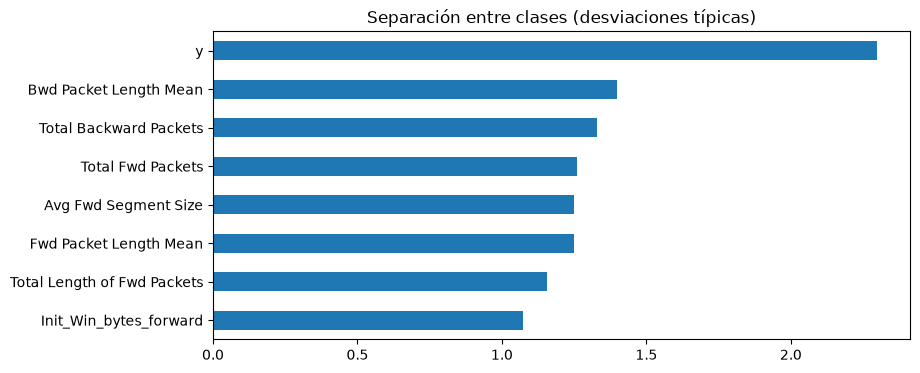

                      n  ataque
Destination Port               
80.0              22411   0.601
443.0             18933   0.080
53.0               8933   0.000
22.0               2275   0.000
8080.0             2185   0.000
3389.0              845   0.000


In [84]:
# ¿Qué columnas separan más las clases? Diferencia de medias estandarizadas
Z = (
    (df[num] - df[num].mean())
    / df[num].std().replace(0, 1)
)
# selecciona flujos de ataque Z[df.y == 1] 
# y flujos benignos Z[df.y == 0], 
# calcula la media de cada uno y las resta
dif = (
        Z[df.y == 1].mean() - Z[df.y == 0].mean()
).abs().sort_values(ascending=False)

dif.head(8).plot.barh(
        title="Separación entre clases (desviaciones típicas)"
)
plt.gca().invert_yaxis()
plt.show()

# ¿Qué puertos concentran el ataque?
# Agrupa por puerto de destino, calcula el tamaño (cuantos items hay en el grupo)
# Calcula la media de la columna y (ataque) para cada grupo
print(df.groupby("Destination Port").agg(n=("y", "size"), ataque=("y", "mean"))
        .sort_values("n", ascending=False).head(6).round(3))


#### ALERTA
Este bloque utiliza todo el dataset para explorar las diferencias entre clases.

Como exploración descriptiva del laboratorio resulta útil.

Pero si utilizamos esa información para seleccionar las mejores características  
antes de dividir el dataset en entrenamiento y prueba, podemos introducir fuga de información.

#### ¿Qué significa una diferencia elevada?
Significa que el valor medio de esa característica es relativamente distinto entre las clases.  
Esto puede indicar que la característica resulta útil para distinguirlas.

Sin embargo:

Una gran diferencia de medias no garantiza que la característica sea un buen predictor.  
Las distribuciones pueden solaparse mucho. También puede ocurrir lo contrario: dos clases  
pueden tener la misma media, pero distribuciones muy diferentes.

Por ejemplo:
Clase A: [-10, 10]
Clase B: [0, 0]

Ambas tienen media cero. Sin embargo, su comportamiento estadístico es claramente diferente.

#### Interpretación de resultados
El 60,1 % de los flujos dirigidos al puerto 80 están etiquetados como ataques.  
Esto NO significa que el 60,1 % de todos los ataques utilicen ese puerto.  
Son probabilidades diferentes.
$$
P(Ataque\mid Puerto=80)
$$
significa:
¿Qué proporción de conexiones al puerto 80 son ataques?

En cambio:
$$
P(Puerto=80\mid Ataque)
$$
significa:
¿Qué proporción de los ataques utilizan el puerto 80?

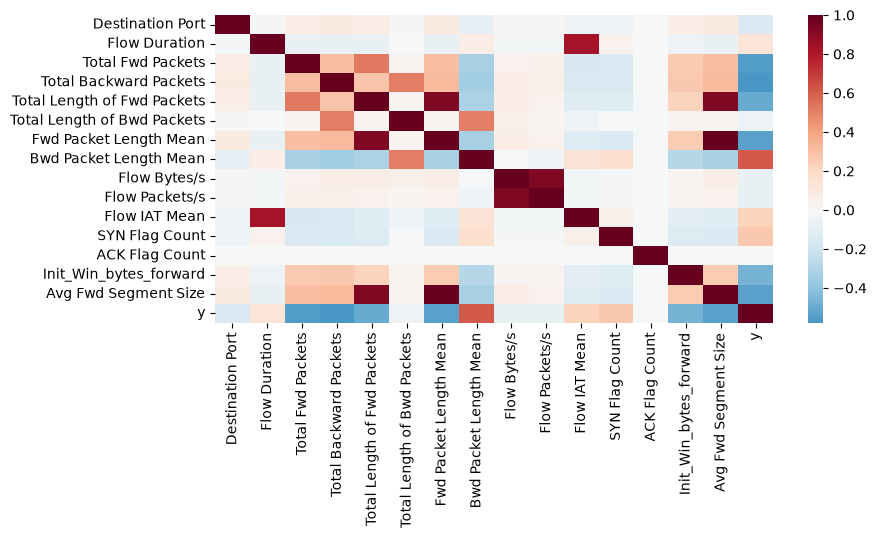

In [86]:
# Correlaciones: columnas casi idénticas son redundantes
# Esto ocurre porque el propio generador asigna los mismos valores a ambas columnas.
import seaborn as sns
sns.heatmap(df[num].corr().round(2), cmap="RdBu_r", center=0)
plt.show()

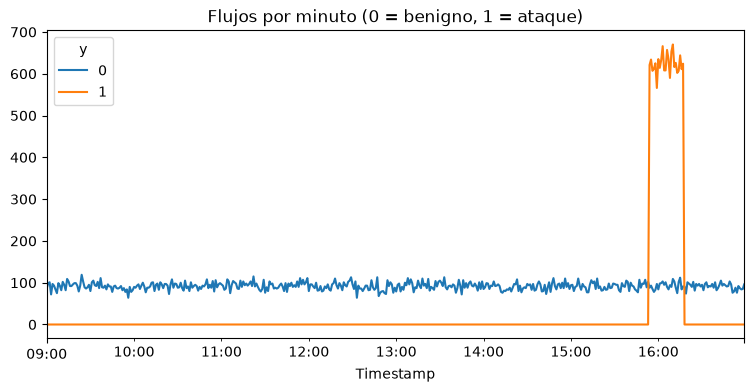

In [87]:
# Línea de tiempo: flujos por minuto y por clase
# Convierte la columna temporal en el índice.
# groupby("y") → Separa los flujos por clase:
# resample("1min") → Agrupa las observaciones en intervalos de un minuto.
# unstack(0) → Convierte la columna y en columnas separadas.
# fillna(0) → Rellena con 0 los minutos sin valor.
serie = df.set_index("Timestamp").groupby("y").resample("1min").size().unstack(0).fillna(0)
serie.plot(title="Flujos por minuto (0 = benigno, 1 = ataque)")
# Vemos que los ataques se concentran entre las 15:54 y 16:18
plt.show()

#### ¿Por qué nos Joden las características redundantes?
Porque pueden:
- Aumentar el consumo de memoria.
- Incrementar el coste computacional.
- Dificultar la interpretación.
- Provocar problemas de multicolinealidad en determinados modelos.
- Dar más peso indirectamente a un mismo fenómeno en algunos algoritmos basados en distancias.
La multicolinealidad aparece cuando existen relaciones lineales fuertes entre varias variables predictoras.

No afecta a todos los modelos de la misma manera.

Por ejemplo, un árbol de decisión puede funcionar razonablemente bien con características correlacionadas, mientras que interpretar los coeficientes individuales de una regresión logística puede volverse más difícil.

#### ¿Por qué a veces es mejor Joderse que quitarlas?
Una correlación elevada es una señal para investigar.

Antes de eliminar una característica deberíamos comprobar:
- Si es exactamente duplicada.
- Si aporta información adicional.
- Si resulta más fácil de calcular que la otra.
- Si cambia la capacidad predictiva del modelo.
- Si alguna de las dos está disponible en producción.
Conclusión: correlación no significa causalidad, ni implica automáticamente que debamos eliminar una columna.

**Reto avanzado.** Opcional con datos reales: descarga un CSV de CICIDS2017 (MachineLearningCVE, web del Canadian Institute for Cybersecurity), súbelo junto al cuaderno y repite la parte B. Pista: `pd.read_csv(ruta, usecols=...)` para ahorrar memoria.

**Objetivo**: Comprobar si los procedimientos de limpieza y exploración que hemos aprendido siguen siendo útiles cuando los datos proceden de capturas de tráfico y no de un generador diseñado para el ejercicio.

In [89]:
import pandas as pd
import numpy as np

ruta = "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

columnas = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Label"
]

try:
    real = pd.read_csv(
        ruta,
        usecols=lambda col: col.strip() in columnas,
        low_memory=False
    )


    real.columns = real.columns.str.strip()

    print(real.shape)
    print(real["Label"].value_counts())

    # Esto reproduce la metodología de la parte B.
    # No obstante, una auditoría de datos más rigurosa debería
    # justificar la eliminación de cada tipo de registro.
    # También deberíamos comprobar cómo afecta la limpieza a la distribución de las clases.
    recuento_original = len(real)

    real = real.replace([np.inf, -np.inf], np.nan)

    print("Nulos por columna:")
    print(real.isna().sum())

    print("Duplicados:")
    print(real.duplicated().sum())

    real = real.dropna().drop_duplicates().reset_index(drop=True)

    real["y"] = (real["Label"] != "BENIGN").astype(int)

    print("Filas eliminadas:", recuento_original - len(real))
    print("Ataques:", real["y"].mean() * 100, "%")


except FileNotFoundError:
    print(f"El archivo {ruta} no se encuentra en el directorio actual.")

El archivo Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv no se encuentra en el directorio actual.


En datos reales podemos encontrar:
- Mayor variedad de protocolos y servicios.
- Distribuciones menos regulares.
- Diferentes familias de ataques.
- Campos adicionales.
- Mayor desequilibrio entre clases.
- Problemas de calidad específicos del proceso de captura.
- Dependencias entre observaciones.

Se recomienda `usecols` Porque algunos CSV contienen muchas columnas y pueden consumir bastante memoria.  
Si únicamente necesitamos analizar determinadas características, podemos leer solo esas columnas.

La principal diferencia entre los datos sintéticos y los reales es que en los datos reales no controlamos  
los patrones que queremos que el algoritmo descubra.

## Parte C · La API de scikit-learn
Todos los modelos siguen el mismo contrato: `modelo.fit(X, y)` y `modelo.predict(X)`. El **baseline** (predecir siempre la clase mayoritaria) es el suelo que cualquier modelo debe superar.

In [79]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
feats = ["duration", "src_bytes", "dst_bytes", "count", "srv_count", "serror_rate", "rerror_rate",
         "same_srv_rate", "diff_srv_rate", "dst_host_count", "dst_host_srv_count", "logged_in"]
Xtr, ytr, Xte, yte = tr[feats], tr.is_attack, te[feats], te.is_attack
for nombre, m in [("baseline", DummyClassifier(strategy="most_frequent")),
                  ("logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
                  ("árbol", DecisionTreeClassifier(max_depth=6, random_state=0))]:
    m.fit(Xtr, ytr)
    print(f"{nombre:10s} acc_train={m.score(Xtr, ytr):.3f}  acc_test={m.score(Xte, yte):.3f}")

baseline   acc_train=0.535  acc_test=0.431
logística  acc_train=0.907  acc_test=0.732
árbol      acc_train=0.977  acc_test=0.778


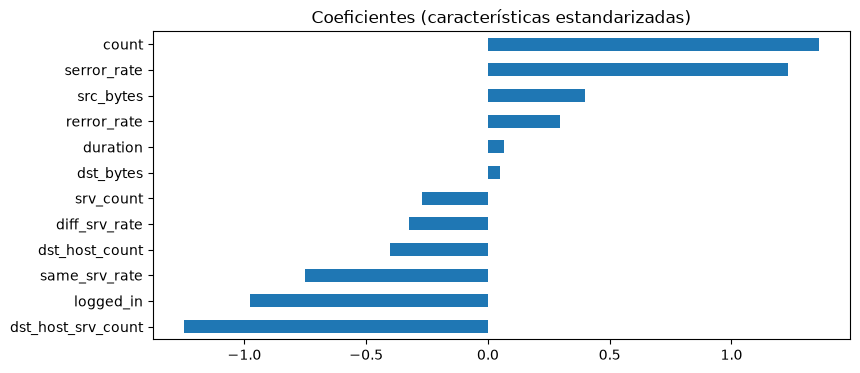

[[0.008 0.992]
 [0.02  0.98 ]
 [0.667 0.333]
 [0.519 0.481]
 [0.347 0.653]]


In [80]:
log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
pesos = pd.Series(log[-1].coef_[0], index=feats).sort_values()
pesos.plot.barh(title="Coeficientes (características estandarizadas)"); plt.show()
print(log.predict_proba(Xte)[:5].round(3))      # columnas: P(normal), P(ataque)

**Qué deberías ver:** el baseline acierta en torno al 43 % en test (predice siempre «normal») y los modelos lo superan. `predict_proba` devuelve dos columnas que suman 1.

**Reto avanzado.** Cambia `LogisticRegression` por `RandomForestClassifier(n_estimators=100, random_state=0)` modificando **una sola línea** y compara. Después aplica el mismo flujo a los flujos de la parte B con `train_test_split(..., stratify=df.y, test_size=0.3, random_state=0)`. ¿Por qué ahí la exactitud es casi perfecta y por qué no debes extrapolarla?

In [ ]:
# Tu código

## Parte D · k-NN a mano
k-NN clasifica un flujo nuevo **por votación de sus k vecinos más cercanos**. Implementarlo obliga a usar todo lo de la parte A.

In [81]:
from sklearn.neighbors import KNeighborsClassifier
rng = np.random.default_rng(0)
i_tr = rng.choice(len(Xtr), 5000, replace=False); i_te = rng.choice(len(Xte), 1000, replace=False)
sc = StandardScaler().fit(Xtr.iloc[i_tr])
A, B = sc.transform(Xtr.iloc[i_tr]), sc.transform(Xte.iloc[i_te])
ya, yb = ytr.iloc[i_tr].to_numpy(), yte.iloc[i_te].to_numpy()

def knn_predict(A, ya, B, k=5):
    d2 = (B ** 2).sum(1)[:, None] + (A ** 2).sum(1)[None, :] - 2 * B @ A.T   # distancias al cuadrado
    vecinos = np.argpartition(d2, k, axis=1)[:, :k]                            # k más cercanos
    return (ya[vecinos].mean(axis=1) > 0.5).astype(int)                         # voto por mayoría

p_mio = knn_predict(A, ya, B)
p_sk = KNeighborsClassifier(n_neighbors=5).fit(A, ya).predict(B)
print("coinciden con scikit-learn:", (p_mio == p_sk).mean(), "| exactitud:", (p_mio == yb).mean())

coinciden con scikit-learn: 1.0 | exactitud: 0.768


**Qué deberías ver:** coincidencia superior al 99 % con scikit-learn.

**Reto avanzado.** Quita el escalado (usa los datos crudos) y mide la exactitud: `src_bytes` domina las distancias. Después mide el tiempo con 5.000 y con 50.000 puntos de entrenamiento y relaciónalo con la complejidad O(n_train × n_test).

In [ ]:
# Tu código

## Parte E · Guardar y servir un modelo

In [82]:
import joblib
from sklearn.ensemble import RandomForestClassifier
modelo = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=150, random_state=0, n_jobs=-1)).fit(Xtr, ytr)
joblib.dump({"modelo": modelo, "features": feats, "version_sklearn": sklearn.__version__}, "ids_basico.joblib")

def puntuar(fichero_csv):
    paq = joblib.load("ids_basico.joblib")
    nuevos = pd.read_csv(fichero_csv)
    return pd.Series(paq["modelo"].predict_proba(nuevos[paq["features"]])[:, 1], name="p_ataque")

te[feats].head(10).to_csv("muestra.csv", index=False)
print(puntuar("muestra.csv").round(3).tolist())

[1.0, 1.0, 0.033, 0.81, 0.253, 0.0, 0.0, 0.007, 0.0, 0.0]


**Qué deberías ver:** diez probabilidades de ataque.

**Por qué se guardan `features` y la versión:** si el CSV trae las columnas en otro orden, la función las reordena por nombre; un modelo serializado solo es fiable con la misma versión de scikit-learn. Y **cargar un pickle de origen desconocido es ejecutar código ajeno**.

**Reto avanzado.** Guarda `muestra.csv` con las columnas en orden inverso y comprueba que `puntuar` sigue dando lo mismo. ¿Qué pasaría si `puntuar` usara `nuevos.to_numpy()` directamente?

In [ ]:
# Tu código

## Parte F · Ampliación: del log de autenticación a un detector
100.000 inicios de sesión sintéticos con una ráfaga de fuerza bruta inyectada contra `u007`.

In [83]:
rng = np.random.default_rng(3); n = 100_000
logs = pd.DataFrame({"t": pd.to_datetime("2026-01-05") + pd.to_timedelta(rng.integers(0, 7 * 86400, n), unit="s"),
                     "user": rng.choice([f"u{i:03d}" for i in range(200)], n),
                     "ip": rng.choice([f"10.10.10.{i}" for i in range(2, 60)], n), "ok": rng.random(n) > 0.05})
rafaga = pd.DataFrame({"t": pd.Timestamp("2026-01-07 03:00") + pd.to_timedelta(rng.integers(0, 600, 300), unit="s"),
                       "user": "u007", "ip": "10.10.10.44", "ok": False})
logs = pd.concat([logs, rafaga], ignore_index=True).sort_values("t")
logs["fallo"] = ~logs["ok"]
v = (logs.set_index("t").groupby("user").resample("10min")
       .agg(intentos=("ok", "size"), fallos=("fallo", "sum"), ips=("ip", "nunique")).reset_index())
v = v[v.intentos > 0].copy()
v["tasa_fallo"] = v.fallos / v.intentos
print(v.sort_values("fallos", ascending=False).head(5))

        user                   t  intentos  fallos  ips  tasa_fallo
7338    u007 2026-01-07 03:00:00       301     300    2    0.996678
112036  u111 2026-01-08 14:10:00         2       2    2    1.000000
149805  u149 2026-01-05 12:50:00         4       2    4    0.500000
34548   u034 2026-01-07 16:10:00         2       2    2    1.000000
179327  u178 2026-01-08 03:00:00         3       2    3    0.666667


**Reto avanzado.** Aplica `IsolationForest(contamination=0.001, random_state=0)` sobre `[intentos, fallos, ips, tasa_fallo]` y comprueba que la ventana de `u007` queda entre las más anómalas. Compara con una regla de umbral: ¿qué falsos positivos aparecen en cada enfoque?

In [ ]:
# Tu código

## Entrega
Reinicia y ejecuta todo. Entrega `ia3_pila.ipynb` y `ids_basico.joblib`. Criterio: el k-NN propio coincide con scikit-learn y justificas por qué escalar y por qué existe un baseline.